# Phần Đức (2/2) — Decision Tree trên Luồng A và Luồng B

**Decision Tree** chia dữ liệu bằng các câu hỏi dạng *"đặc trưng ≤ ngưỡng?"*. Tại mỗi nút, cây chọn câu hỏi
làm các nút con "thuần" nhất, đo bằng Gini $G = 1 - \sum_k p_k^2$ hoặc Entropy $H = -\sum_k p_k \log_2 p_k$.
Cây quá sâu sẽ học thuộc dữ liệu (overfitting) nên cần giới hạn `max_depth`, `min_samples_leaf`.
Dữ liệu có 26,5% Churn nên thử thêm `class_weight="balanced"` để tăng trọng số lớp rời bỏ.

**Quy trình:** GridSearchCV 5-fold chỉ trên Train, chọn tham số theo **F1 của lớp Churn = Yes**,
sau đó đánh giá một lần trên tập Test chung của Mạnh.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "config.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.config import POSITIVE_LABEL
from src.evaluate import danh_gia_mo_hinh
from src.train_decision_tree import (
    PARAM_GRID, doc_du_lieu, luu_ket_qua, tim_tham_so, ve_cay, ve_confusion_matrix, ve_feature_importance,
)

PARAM_GRID

{'criterion': ['gini', 'entropy'],
 'max_depth': [3, 4, 5, 6, 7, 8, 10, 12, None],
 'min_samples_leaf': [1, 5, 10, 20, 30, 50, 75, 100],
 'class_weight': [None, 'balanced']}

## 1. Tìm tham số trên Train

In [2]:
search, du_lieu = {}, {}
for luong in ["A", "B"]:
    du_lieu[luong] = doc_du_lieu(luong)
    X_train, X_test, y_train, y_test = du_lieu[luong]
    search[luong] = tim_tham_so(X_train, y_train)
    print(f"Luồng {luong} ({X_train.shape[1]} cột): {search[luong].best_params_}, F1 CV = {search[luong].best_score_:.4f}")

Luồng A (45 cột): {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 50}, F1 CV = 0.6253


Luồng B (17 cột): {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 50}, F1 CV = 0.6254


In [3]:
# 5 tổ hợp tham số tốt nhất của Luồng B
cv = pd.DataFrame(search["B"].cv_results_)
cv[["params", "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False).head()

,params,mean_test_score,std_test_score
253,"{'class_weight': 'balanced', 'criterion': 'ent...",0.625380,0.019604
261,"{'class_weight': 'balanced', 'criterion': 'ent...",0.625085,0.019322
269,"{'class_weight': 'balanced', 'criterion': 'ent...",0.624475,0.018838
285,"{'class_weight': 'balanced', 'criterion': 'ent...",0.624475,0.018838
277,"{'class_weight': 'balanced', 'criterion': 'ent...",0.624475,0.018838


Cả hai luồng chọn `class_weight="balanced"` và `min_samples_leaf=50` (lá đủ lớn nên cây ít bị overfit).
F1 CV gần như bằng nhau (0,6253 và 0,6254), chênh lệch nhỏ hơn nhiều so với độ lệch giữa các fold (khoảng 0,02),
nên hai luồng **tương đương** — nhưng Luồng B chỉ dùng 17 cột thay vì 45.

## 2. Đánh giá trên tập Test

In [4]:
du_doan, bang = {}, []
for luong in ["A", "B"]:
    X_train, X_test, y_train, y_test = du_lieu[luong]
    print(f"\n########## Luồng {luong} ##########")
    du_doan[luong] = search[luong].best_estimator_.predict(X_test)
    metrics = danh_gia_mo_hinh(y_test, du_doan[luong], pos_label=POSITIVE_LABEL)
    luu_ket_qua(luong, search[luong], metrics)   # lưu JSON cho Hùng + mô hình
    bang.append({"Luồng": luong, **{k: round(metrics[k], 4) for k in ["accuracy", "precision", "recall", "f1_score"]}})

pd.DataFrame(bang).set_index("Luồng")


########## Luồng A ##########
===== KẾT QUẢ ĐÁNH GIÁ =====
Accuracy : 0.7488
Precision: 0.5175
Recall   : 0.7914
F1-score : 0.6258

===== CONFUSION MATRIX =====
[[759, 276], [78, 296]]

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.91      0.73      0.81      1035
         Yes       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409


########## Luồng B ##########
===== KẾT QUẢ ĐÁNH GIÁ =====
Accuracy : 0.7346
Precision: 0.5000
Recall   : 0.7995
F1-score : 0.6152

===== CONFUSION MATRIX =====
[[736, 299], [75, 299]]

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.91      0.71      0.80      1035
         Yes       0.50      0.80      0.62       374

    accuracy                           0.73      1409
   macro avg 

,accuracy,precision,recall,f1_score
Luồng,,,,
A,0.7488,0.5175,0.7914,0.6258
B,0.7346,0.5000,0.7995,0.6152


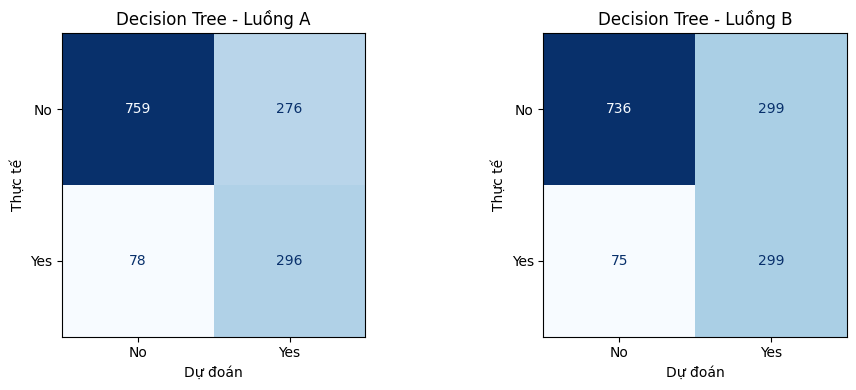

In [5]:
fig = ve_confusion_matrix(y_test, du_doan)

- Luồng A: bắt được 296/374 khách rời bỏ (Recall 0,7914), F1 0,6258.
- Luồng B: bắt được 299/374 khách rời bỏ (Recall 0,7995), F1 0,6152 — bắt thêm 3 khách nhưng báo nhầm thêm 23 khách ở lại.
- Accuracy (0,73–0,75) không cao hơn bao nhiêu so với việc luôn đoán "No" (0,7346), nhưng Recall gần 0,8 thay vì 0.
  Vì vậy với bài toán Churn **không thể chỉ nhìn Accuracy**.

## 3. Đặc trưng quan trọng và cấu trúc cây

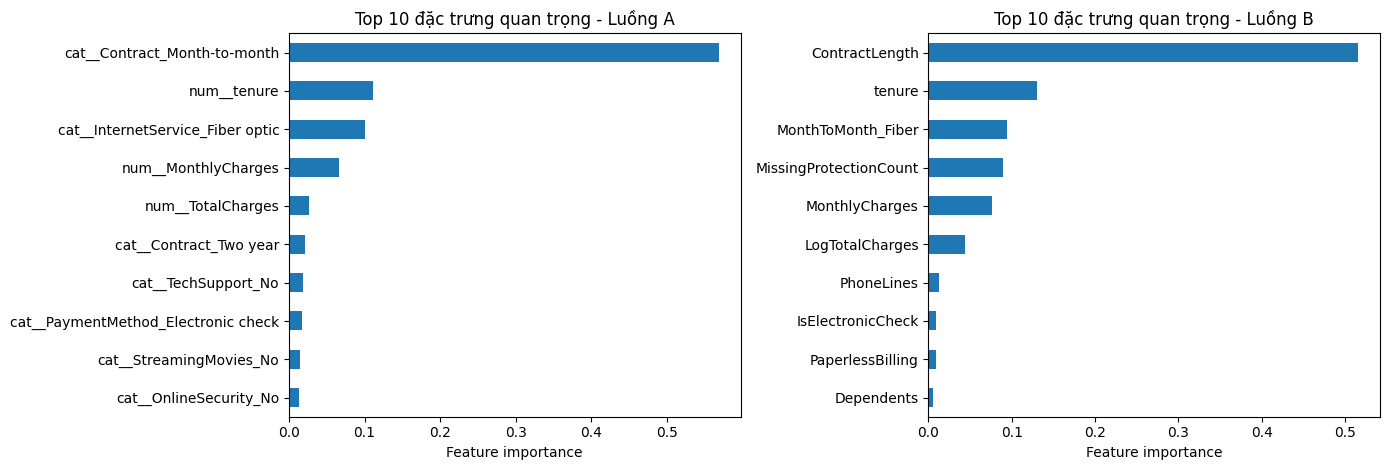

In [6]:
mo_hinh = {l: search[l].best_estimator_ for l in ["A", "B"]}
ten_cot = {l: du_lieu[l][0].columns for l in ["A", "B"]}
fig = ve_feature_importance(mo_hinh, ten_cot)

Hai luồng đều cho thấy **loại hợp đồng** quan trọng nhất (hơn 50%), sau đó là `tenure`.
Ở Luồng B, hai đặc trưng mới **`MonthToMonth_Fiber`** và **`MissingProtectionCount`** đứng thứ 3 và 4.

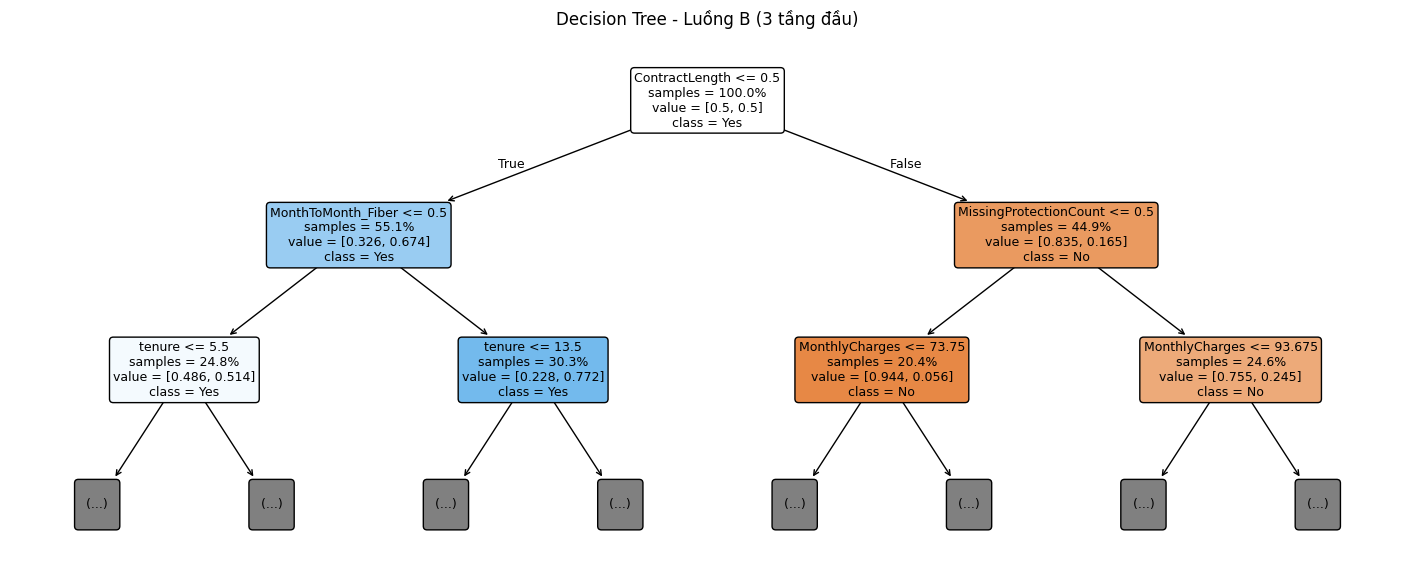

In [7]:
fig = ve_cay(mo_hinh["B"], ten_cot["B"])

Cây Luồng B tách trước hết theo **hợp đồng theo tháng** (`ContractLength ≤ 0.5`), sau đó theo
**hợp đồng tháng + Fiber optic** và **tenure**; nhánh hợp đồng dài hạn tách theo **số dịch vụ bảo vệ còn thiếu**
và **MonthlyCharges**. Các quy tắc này khớp với EDA và dễ giải thích.
(`value` là tỷ lệ lớp sau khi cân bằng trọng số do `class_weight="balanced"`.)

## 4. Kết luận

| Luồng | Tham số tốt nhất | F1 CV | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|---|
| A (45 cột) | gini, max_depth=8, min_samples_leaf=50, balanced | 0,6253 | 0,7488 | 0,5175 | 0,7914 | 0,6258 |
| B (17 cột) | entropy, max_depth=7, min_samples_leaf=50, balanced | 0,6254 | 0,7346 | 0,5000 | 0,7995 | 0,6152 |

Hai luồng cho kết quả tương đương; Luồng B gọn hơn và dễ giải thích hơn.
Đã gửi Hùng: `results/duc_decision_tree_A.json`, `results/duc_decision_tree_B.json`.